[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E8%8C%B6%E8%AA%9E%E6%99%82%E5%85%89_%E8%80%81%E9%97%86%E6%9C%80%E6%84%9B%E7%9A%84%E4%BA%94%E5%BC%B5%E5%9C%96.ipynb)

# 📈 茶語時光：做出老闆最愛的五張圖

> 🧋 **情境**：年終檢討會議就在明天，老闆說：「我不要看密密麻麻的表格，給我幾張圖，一眼就知道今年哪家店最好、什麼最好賣、客人是誰、天氣對生意有沒有影響。」你決定用 Matplotlib 做出五張圖，再組成一頁儀表板。

| 素材檔案 | 內容 |
| --- | --- |
| `門市月營收_2024.csv` | 5 家門市 2024 年每月營收（萬元） |
| `品項年銷量_2024.csv` | 10 個品項全年銷量 |
| `西門店每日氣溫與銷量_2024.csv` | 西門店每天的最高溫與芒果冰沙、熱可可杯數 |
| `會員年齡.csv` | 700 位會員的年齡 |
| `甜度偏好_2024.csv` | 一年來各甜度的杯數（抽樣） |

> ⚠️ 「茶語時光」是課程虛構的品牌，資料為模擬資料；節日與颱風假的日期參考台灣實際情況，方便你對照生活經驗。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '門市月營收_2024.csv',
    '品項年銷量_2024.csv',
    '西門店每日氣溫與銷量_2024.csv',
    '會員年齡.csv',
    '甜度偏好_2024.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['門市月營收_2024.csv', '品項年銷量_2024.csv', '西門店每日氣溫與銷量_2024.csv', '會員年齡.csv', '甜度偏好_2024.csv']


In [2]:
# 🈶 設定圖表中文字型（避免中文變成方塊）
import os, urllib.request
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_chinese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ['Noto Sans CJK TC', 'Microsoft JhengHei', 'PingFang TC', 'Heiti TC', 'Arial Unicode MS']:
        if name in installed:                       # 電腦裡已經有中文字型就直接用
            plt.rcParams['font.sans-serif'] = [name]
            break
    else:                                           # 沒有（例如 Colab）就下載課程提供的字型
        path = 'ChineseFont.ttf'
        if not os.path.exists(path):
            urllib.request.urlretrieve('https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%B9%AA%E5%9C%96%E5%92%8C%E8%A6%96%E8%A6%BA%E5%B1%95%E7%A4%BA/ChineseFont.ttf', path)
        font_manager.fontManager.addfont(path)
        plt.rcParams['font.sans-serif'] = [font_manager.FontProperties(fname=path).get_name()]
    plt.rcParams['axes.unicode_minus'] = False      # 負號正常顯示

setup_chinese_font()
print('✅ 中文字型設定完成：', plt.rcParams['font.sans-serif'][0])

✅ 中文字型設定完成： Microsoft JhengHei


## 圖 1：哪家店今年最好？——折線圖看趨勢

**老闆的問題**：「五家店一整年的營收走勢如何？有沒有淡旺季？」

**白話說明**：「隨時間變化」用折線圖。X 軸放月份，Y 軸放營收，每家店一條線。

    台北信義店  台北西門店  台中逢甲店  台南成大店  高雄巨蛋店
月份                                   
1月   50.2   55.7   68.1   49.6   57.7
2月   47.8   53.0   64.0   47.0   54.0
3月   59.0   67.9   77.7   53.1   65.7


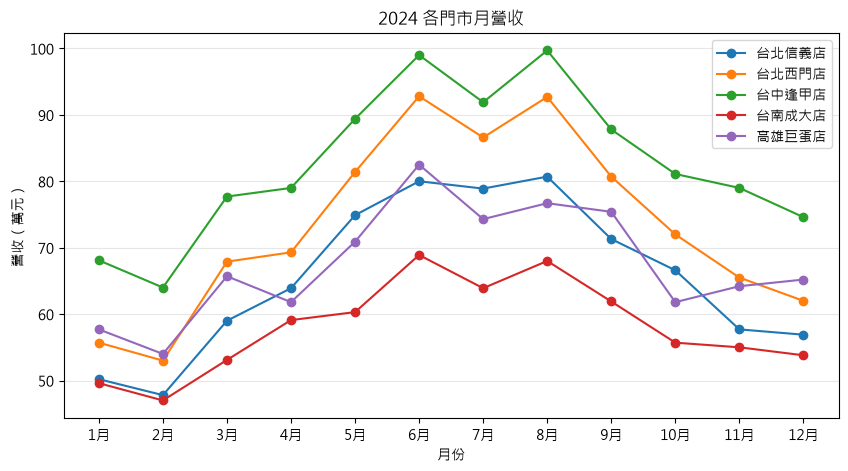

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

monthly = pd.read_csv('門市月營收_2024.csv', index_col='月份')   # 讀取月營收，月份當索引
print(monthly.head(3))

fig, ax = plt.subplots(figsize=(10, 5))                        # 建立畫布與畫框
for store in monthly.columns:                                  # 每家店畫一條線
    ax.plot(monthly.index, monthly[store], marker='o', label=store)
ax.set_title('2024 各門市月營收')                               # 標題
ax.set_xlabel('月份')
ax.set_ylabel('營收（萬元）')
ax.grid(axis='y', alpha=0.3)                                   # 淡淡的水平格線
ax.legend()                                                    # 圖例
plt.show()

> 💡 **看懂結果**：五條線都是「夏天高、冬天低」——天氣熱，飲料就好賣。台中逢甲店整年都是第一名；7 月雖然最熱，但遇到凱米颱風停班停課，成長被打斷了一下。
>
> 🤖 **換你問 AI**：「請用 matplotlib 畫 5 家門市 12 個月營收的折線圖，每家店一條線加圓點，標題『2024 各門市月營收』，並設定繁體中文字型。」

## 圖 2：什麼最好賣？——排序長條圖＋數值標註

**老闆的問題**：「十個品項裡，哪幾杯是台柱？哪幾杯可以考慮下架？」

**白話說明**：「比較大小」用長條圖。品項名稱很長時，用**水平長條**（`barh`）比較好讀；排序後再標上數字，簡報時一目了然。

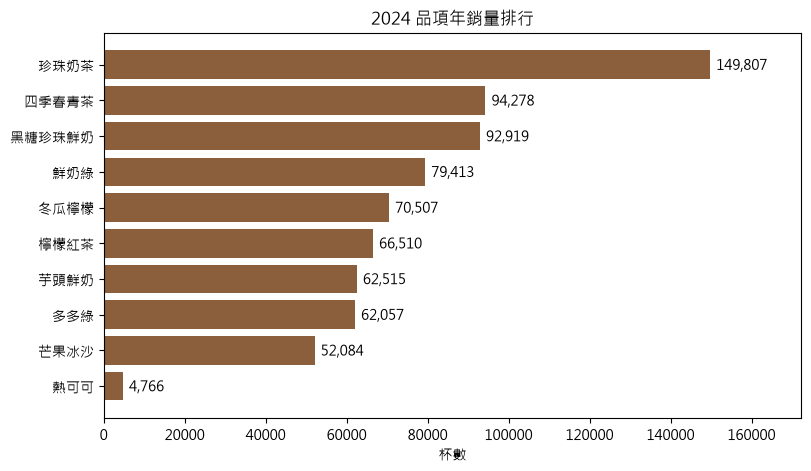

In [4]:
items = pd.read_csv('品項年銷量_2024.csv', index_col='品項')['年銷量(杯)'].sort_values()   # 由小到大排序（畫水平長條時最大的會在最上面）

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(items.index, items.values, color='#8B5E3C')     # 水平長條圖，奶茶色
for bar, v in zip(bars, items.values):                         # 在每根長條右邊標上數字
    ax.text(v + 1500, bar.get_y() + bar.get_height() / 2, f'{v:,}', va='center')
ax.set_title('2024 品項年銷量排行')
ax.set_xlabel('杯數')
ax.set_xlim(0, items.max() * 1.15)                             # 右邊留空間放數字
plt.show()

> 💡 **看懂結果**：珍珠奶茶遙遙領先，是品牌的台柱。4 月才上市的芋頭鮮奶全年總量看起來不高，但它只賣了 9 個月——換算成「每月平均」就一點也不輸老品項（練習時可以算算看）。熱可可只有冬天賣，總量最少，但它是冬天的重要商品。**比較之前，先確認大家的基準（期間）是否一致。**
>
> 🤖 **換你問 AI**：「請把這份品項銷量畫成由大到小的水平長條圖，長條右側標上千分位數字。」

## 圖 3：我們的客人是誰？——直方圖看分布

**老闆的問題**：「會員大概幾歲？行銷活動要針對誰？」

**白話說明**：想知道「數字集中在哪個範圍」用直方圖：把年齡切成一格一格的區間，數每一格有幾個人。

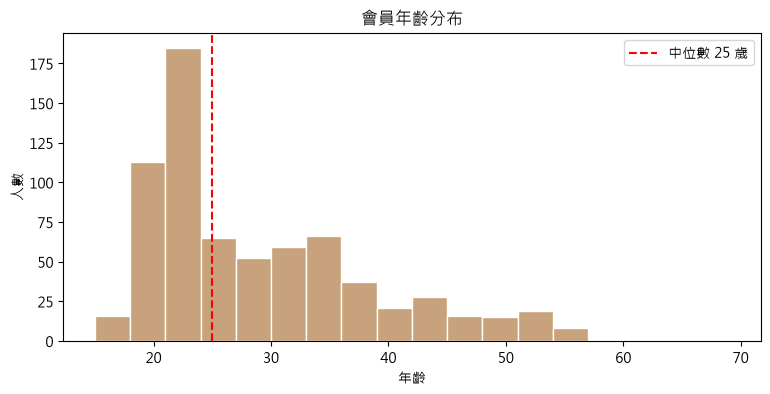

In [5]:
ages = pd.read_csv('會員年齡.csv')['年齡']

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ages, bins=range(15, 72, 3), color='#C8A27C', edgecolor='white')   # 每 3 歲一個區間
ax.axvline(ages.median(), color='red', linestyle='--', label=f'中位數 {ages.median():.0f} 歲')  # 畫一條中位數參考線
ax.set_title('會員年齡分布')
ax.set_xlabel('年齡')
ax.set_ylabel('人數')
ax.legend()
plt.show()

> 💡 **看懂結果**：分布有**兩座山**：20 歲出頭的大學生，和 30 歲左右的上班族。只看「平均年齡」會得到一個兩邊都不像的數字——這就是為什麼一定要畫圖看分布。

## 圖 4：大家都喝幾分糖？——圓餅圖看比例

**老闆的問題**：「要不要推『微糖、無糖』的健康系列？」

**白話說明**：「各部分佔整體幾成」用圓餅圖。類別不要超過 5～6 個，太多就改用長條圖。

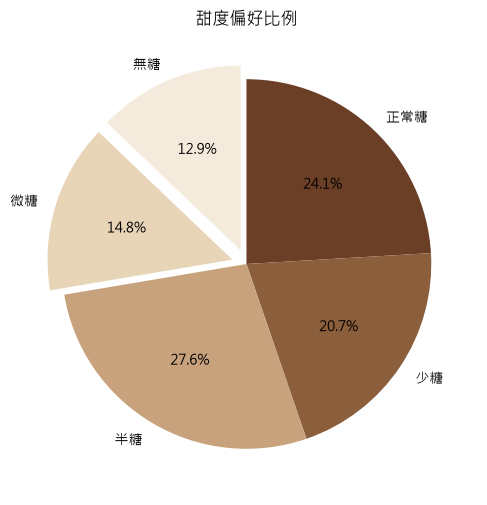

In [6]:
sweet = pd.read_csv('甜度偏好_2024.csv', index_col='甜度')['杯數']

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sweet.values, labels=sweet.index,
       autopct='%1.1f%%',                                      # 自動顯示百分比
       startangle=90, counterclock=False,                      # 從 12 點鐘方向順時針排列
       explode=[0, 0, 0, 0.08, 0.08],                          # 把微糖、無糖往外拉，強調健康系列
       colors=['#6B3E26', '#8B5E3C', '#C8A27C', '#E8D5B7', '#F5EBDD'])
ax.set_title('甜度偏好比例')
plt.show()

> 💡 **看懂結果**：微糖加無糖接近三成，是不小的族群——推出健康系列有市場。

## 圖 5：天氣越熱，冰沙越好賣嗎？——散佈圖看關係

**老闆的問題**：「芒果冰沙跟熱可可要備多少料，可以看天氣決定嗎？」

**白話說明**：想看「兩個數字有沒有關係」用散佈圖：每一天是一個點，X 是氣溫，Y 是杯數。

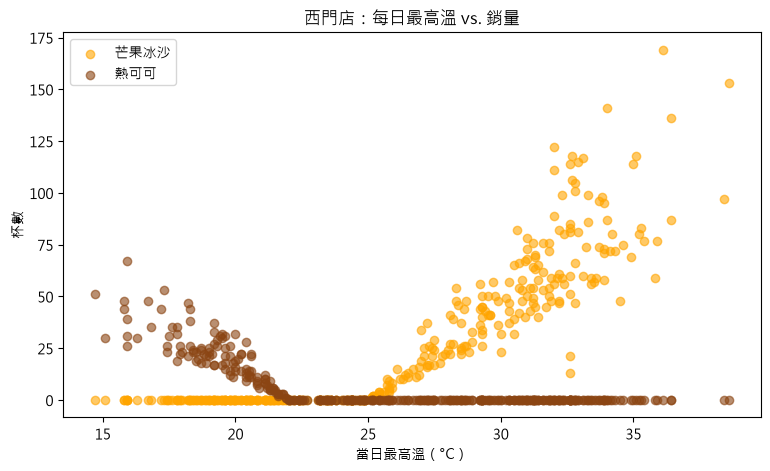

In [7]:
daily = pd.read_csv('西門店每日氣溫與銷量_2024.csv')

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(daily['最高溫'], daily['芒果冰沙'], alpha=0.6, label='芒果冰沙', color='orange')
ax.scatter(daily['最高溫'], daily['熱可可'], alpha=0.6, label='熱可可', color='saddlebrown')
ax.set_title('西門店：每日最高溫 vs. 銷量')
ax.set_xlabel('當日最高溫（°C）')
ax.set_ylabel('杯數')
ax.legend()
plt.show()

> 💡 **看懂結果**：兩種飲料剛好是「交叉」的——超過 25 度冰沙開始大賣、越熱賣越多；低於 22 度熱可可才有人買。**看氣象預報備料**，就能減少浪費、避免缺貨。
>
> 🤖 **換你問 AI**：「請用散佈圖呈現每日最高溫與芒果冰沙杯數的關係，並加上一條趨勢線，用白話解釋結果。」

## 最後一步：組成一頁儀表板並存檔

**白話說明**：用 `plt.subplots(2, 2)` 在一張畫布上放四張圖，再用 `savefig` 存成高解析度圖片，直接貼進簡報。

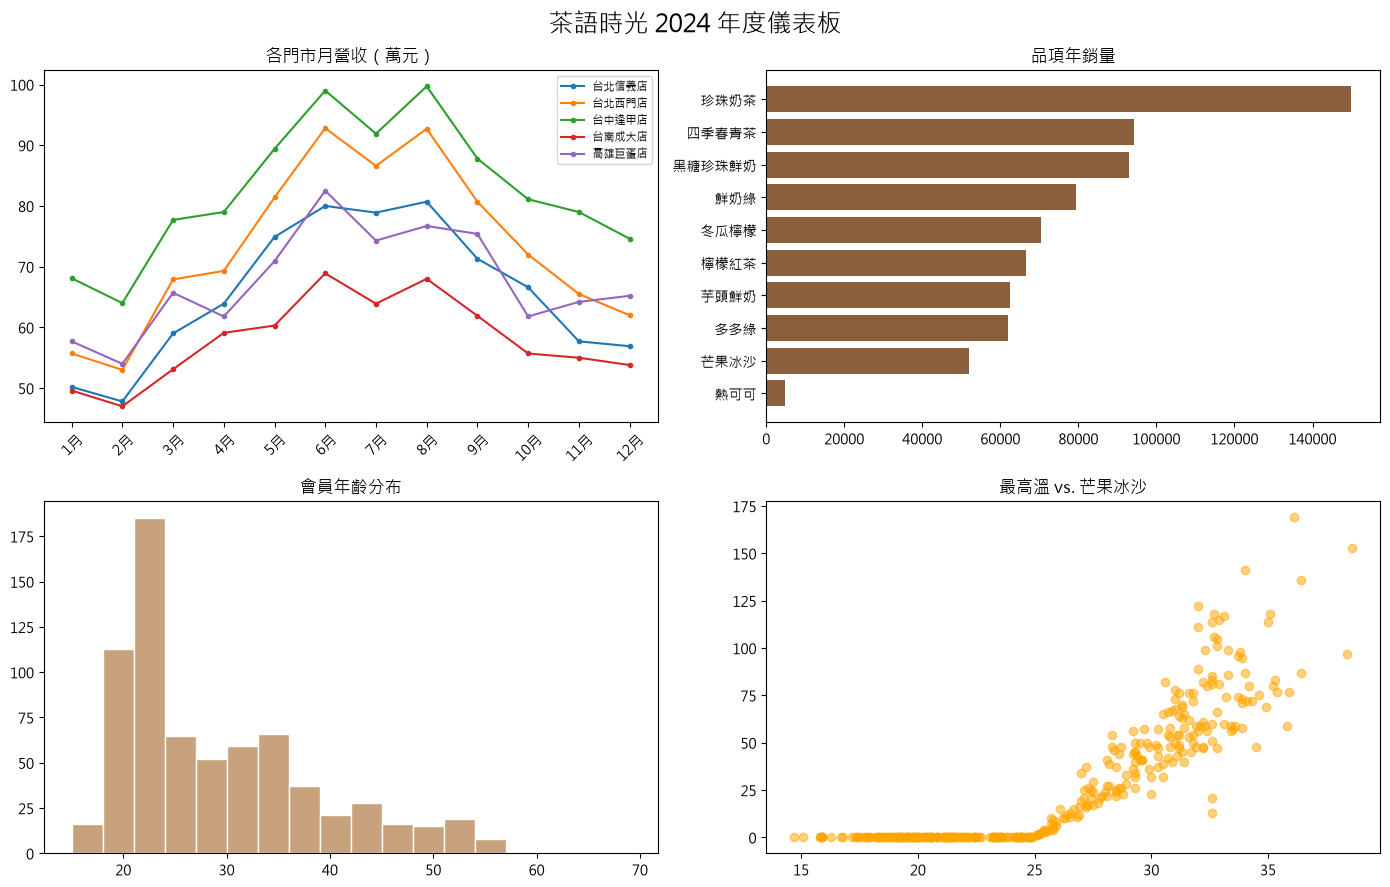

已存成 2024年度儀表板.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for store in monthly.columns:                                          # 左上：月營收
    axes[0, 0].plot(monthly.index, monthly[store], marker='.', label=store)
axes[0, 0].set_title('各門市月營收（萬元）')
axes[0, 0].legend(fontsize=8)
axes[0, 0].tick_params(axis='x', rotation=45)

axes[0, 1].barh(items.index, items.values, color='#8B5E3C')            # 右上：品項銷量
axes[0, 1].set_title('品項年銷量')

axes[1, 0].hist(ages, bins=range(15, 72, 3), color='#C8A27C', edgecolor='white')   # 左下：年齡
axes[1, 0].set_title('會員年齡分布')

axes[1, 1].scatter(daily['最高溫'], daily['芒果冰沙'], alpha=0.5, color='orange')   # 右下：氣溫 vs 冰沙
axes[1, 1].set_title('最高溫 vs. 芒果冰沙')

fig.suptitle('茶語時光 2024 年度儀表板', fontsize=18)
plt.tight_layout()
plt.savefig('2024年度儀表板.png', dpi=200, bbox_inches='tight')        # 存成高解析度圖片
plt.show()
print('已存成 2024年度儀表板.png')

---

## ✍️ 練習題

1. 只畫「台南成大店」的月營收折線圖，並用 `ax.annotate` 在營收最高的月份標上「全年最高」。
2. 畫出西門店「最高溫 vs. 總杯數」的散佈圖，觀察天氣對整體生意的影響。
3. 把圖 2 改成**直立**長條圖（`bar`），由大到小排序，並把 X 軸文字旋轉 45 度。

## 🔑 參考解答（先自己試試看！）

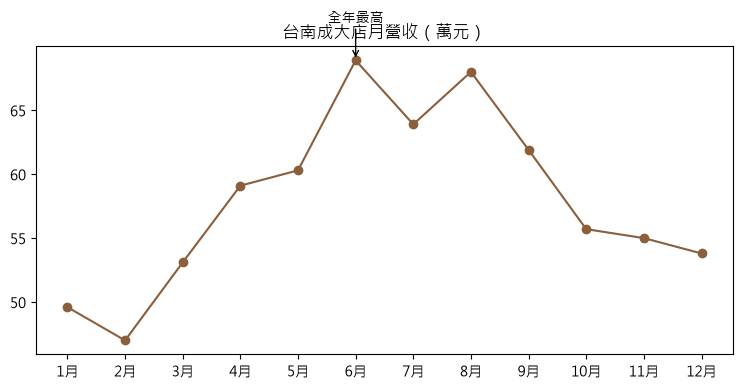

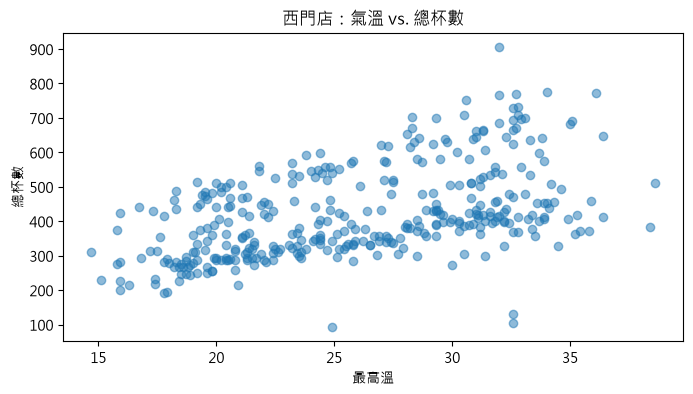

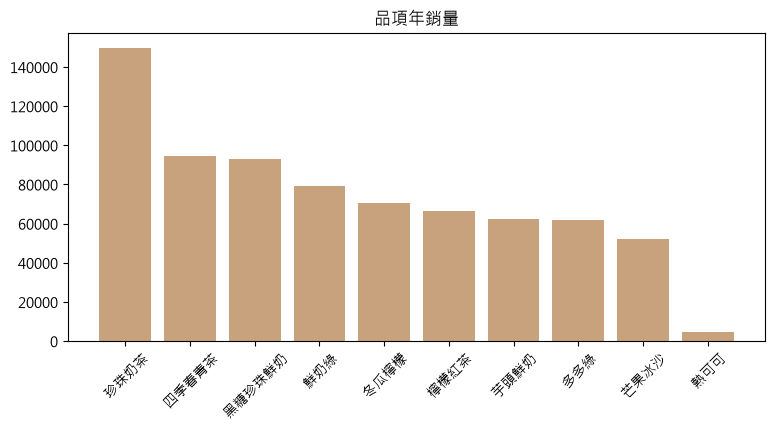

In [9]:
# 練習 1
s = monthly['台南成大店']
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s.index, s.values, marker='o', color='#8B5E3C')
best = s.idxmax()                                                      # 營收最高的月份
ax.annotate('全年最高', xy=(best, s[best]), xytext=(best, s[best] + 3),
            ha='center', arrowprops=dict(arrowstyle='->'))
ax.set_title('台南成大店月營收（萬元）')
plt.show()

# 練習 2
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(daily['最高溫'], daily['總杯數'], alpha=0.5)
ax.set_xlabel('最高溫'); ax.set_ylabel('總杯數'); ax.set_title('西門店：氣溫 vs. 總杯數')
plt.show()

# 練習 3
top = items.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(top.index, top.values, color='#C8A27C')
ax.tick_params(axis='x', rotation=45)
ax.set_title('品項年銷量')
plt.show()